# SHL Hiring Assessment 2026 — Grammar Scoring Engine

## 1–4. Problem, dataset and evaluation
Predict a continuous **0–5 grammar score** from a spoken WAV recording. The supplied data has
769 labeled training clips and 216 unlabeled test clips. Zeros are real training labels; they are
retained. Test `label=-1` values are placeholders and never used for learning.

**RMSE** measures score error in the original units; lower is better. **Pearson correlation**
measures linear agreement in ranking; higher is better. Constant predictions have undefined Pearson.
Both are reported on clipped predictions. Model selection uses development CV Pearson first and RMSE
as a tie-break, following the stated metric priority; the exact leaderboard aggregation was not independently verified.

**Submission correction authorized by the user:** `sample_submission.csv` contains 204 stale IDs.
The output uses its `filename,label` column schema and all 216 filenames in exact `test.csv` order.

**Architecture:** CSV/audio audit → mono 16 kHz waveform → 177 cached acoustic descriptors →
fold-local median imputation / constant removal / scaling → compact regressors →
development CV selection → untouched holdout evaluation → full-data refit → clipped submission.

The notebook is standalone: all required functions appear below. No API, model download or internet is required.

## 5. Environment & imports
Use the installed Kaggle scientific Python packages. Locally, install `requirements.txt`.
`SHL_DATA_DIR` can point to a folder containing the three CSVs and the `train/`, `test/` WAV directories.
Only Kaggle input discovery is automatic; outputs are written to the current writable directory.
Seed 42 and fixed folds are used throughout.

In [1]:
import os, sys, json, hashlib, time, platform
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from threadpoolctl import threadpool_limits
import joblib

RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
FEATURES = Path('features'); FEATURES.mkdir(exist_ok=True)
MODELS = Path('models'); MODELS.mkdir(exist_ok=True)
FIGURES = RESULTS / 'figures'; FIGURES.mkdir(exist_ok=True)
versions = {p: metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','joblib']}
(RESULTS/'environment.json').write_text(json.dumps({'python': sys.version, 'packages': versions}, indent=2))
print('Python:', platform.python_version(), '| Packages:', versions)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

Python: 3.10.11 | Packages: {'numpy': '2.2.6', 'pandas': '2.3.3', 'scipy': '1.15.3', 'scikit-learn': '1.7.2', 'matplotlib': '3.10.8', 'joblib': '1.5.3'}


## 6. Data loading and integrity checks
Filenames are only unique **within** a split: 212 names occur in both train and test.
All joins and cache lookups preserve the split. The audit checks headers, durations, missing records,
sample rate, channels, truncated PCM, and exact audio duplicates. Errors produce a diagnostic report
and stop the run rather than silently dropping samples or fabricating predictions.
Speaker IDs are unavailable, so speaker overlap cannot be ruled out.

In [2]:
"""Strict dataset inspection; IDs are always qualified by split."""
from pathlib import Path
import hashlib
import json
import os
import wave
import numpy as np
import pandas as pd


def find_data_root():
    explicit = os.environ.get('SHL_DATA_DIR')
    if explicit:
        root = Path(explicit)
        if not (root / 'train.csv').is_file():
            raise FileNotFoundError(f'SHL_DATA_DIR has no train.csv: {root}')
        return root
    candidates = [Path('Dataset_Final'), Path('.')]
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('train.csv')]
    valid = [p for p in candidates if all((p / n).is_file() for n in
             ['train.csv', 'test.csv', 'sample_submission.csv'])]
    valid = list(dict.fromkeys(p.resolve() for p in valid))
    if len(valid) != 1:
        raise FileNotFoundError(f'Expected one dataset, found {valid}. Set SHL_DATA_DIR.')
    return valid[0]


def inspect_dataset(root, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    train, test, sample = [pd.read_csv(root / n) for n in
                          ['train.csv', 'test.csv', 'sample_submission.csv']]
    for name, frame in [('train', train), ('test', test), ('sample', sample)]:
        if list(frame.columns) != ['filename', 'label']:
            raise ValueError(f'Unexpected {name} columns: {frame.columns.tolist()}')
        if frame.filename.isna().any() or frame.filename.duplicated().any():
            raise ValueError(f'Missing or duplicate {name} IDs')
        if any(Path(n).name != n for n in frame.filename):
            raise ValueError('Expected plain filenames, not paths')
    if not np.isfinite(train.label).all() or not train.label.between(0, 5).all():
        raise ValueError('Training labels must be finite and in [0, 5]')
    rows = []
    for split, frame in [('train', train), ('test', test)]:
        actual = {p.name for p in (root / split).glob('*.wav')}
        expected = set(frame.filename)
        if actual != expected:
            raise ValueError(f'{split}: missing={expected-actual}, unlisted={actual-expected}')
        for filename in frame.filename:
            path = root / split / filename
            row = {'split': split, 'filename': filename, 'error': ''}
            try:
                with wave.open(str(path)) as wav:
                    channels, width, sr, frames, _, _ = wav.getparams()
                    pcm = wav.readframes(frames)
                    if len(pcm) != frames * channels * width or frames == 0:
                        raise ValueError('Truncated or empty PCM audio')
                    # Include sample rate/channel layout in the duplicate signature.
                    digest = hashlib.sha256(f'{sr}:{channels}:{width}:'.encode() + pcm).hexdigest()
                    row.update(duration=frames/sr, sample_rate=sr, channels=channels,
                               sample_width=width, sha256=digest)
            except Exception as exc:
                row['error'] = f'{type(exc).__name__}: {exc}'
            rows.append(row)
    audit = pd.DataFrame(rows)
    audit.to_csv(output / 'audio_audit.csv', index=False)
    if audit.error.ne('').any():
        raise ValueError('Unreadable audio; see results/audio_audit.csv. No rows silently dropped.')
    if audit.sha256.duplicated().any():
        raise ValueError('Duplicate audio detected. Resolve duplicates/use grouped validation first.')
    report = {
        'train_rows': len(train), 'test_rows': len(test), 'sample_rows': len(sample),
        'columns': list(train.columns), 'target_range': [float(train.label.min()), float(train.label.max())],
        'label_counts': train.label.value_counts().sort_index().to_dict(),
        'missing_values': {n: d.isna().sum().to_dict() for n, d in [('train', train), ('test', test), ('sample', sample)]},
        'duplicate_rows': {n: int(d.duplicated().sum()) for n, d in [('train', train), ('test', test)]},
        'same_filename_across_splits': len(set(train.filename) & set(test.filename)),
        'duplicate_audio': int(audit.sha256.duplicated().sum()),
        'sample_matches_test': sample.filename.tolist() == test.filename.tolist(),
        'sample_test_overlap': len(set(sample.filename) & set(test.filename)),
        'submission_policy': 'User confirmed stale sample IDs; use test.csv IDs/order and sample columns.',
        'sample_rates': audit.sample_rate.value_counts().to_dict(),
        'channels': audit.channels.value_counts().to_dict(),
        'duration_by_split': audit.groupby('split').duration.agg(['min', 'median', 'max']).to_dict(),
    }
    (output / 'data_inspection.json').write_text(json.dumps(report, indent=2), encoding='utf-8')
    return train, test, sample, audit, report

In [3]:
DATA_ROOT = find_data_root()
train, test, sample, audit, data_report = inspect_dataset(DATA_ROOT, RESULTS)
print('Shapes:', {name: frame.shape for name, frame in [('train', train), ('test', test), ('sample', sample)]})
display(train.head(3))
print('Missing values:', data_report['missing_values'])
print('Duplicate rows:', data_report['duplicate_rows'], '| Exact duplicate audio:', data_report['duplicate_audio'])
print('Audio sample rates:', data_report['sample_rates'], '| Channels:', data_report['channels'])
display(audit.groupby('split').duration.agg(['min','median','max']).round(2))
print('Sample/test ID overlap:', data_report['sample_test_overlap'], '| Submission policy:', data_report['submission_policy'])

Shapes: {'train': (769, 2), 'test': (216, 2), 'sample': (204, 2)}


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5


Missing values: {'train': {'filename': 0, 'label': 0}, 'test': {'filename': 0, 'label': 0}, 'sample': {'filename': 0, 'label': 0}}
Duplicate rows: {'train': 0, 'test': 0} | Exact duplicate audio: 0
Audio sample rates: {16000: 985} | Channels: {1: 985}


,min,median,max
split,,,
test,6.48,45.06,61.03
train,20.06,60.07,61.04


Sample/test ID overlap: 25 | Submission policy: User confirmed stale sample IDs; use test.csv IDs/order and sample columns.


## 7. Exploratory data analysis
Label and feature relationships use labeled training data only. Test metadata is audited for integrity,
but test distributions do not drive feature or model selection. The 37 zero scores remain in the task.
Short files are retained rather than trimmed or excluded.

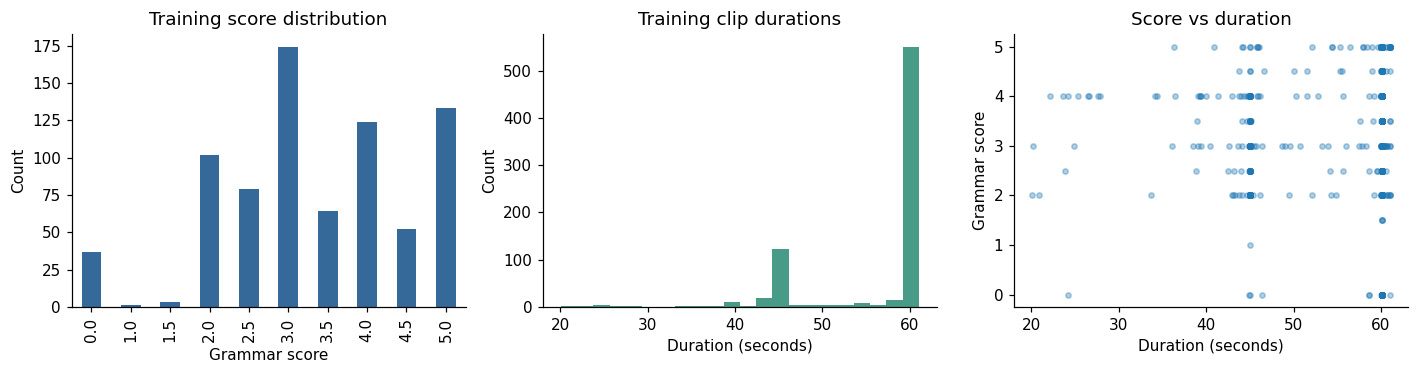

In [4]:
train_meta = train.merge(audit.query("split == 'train'"), on='filename', validate='one_to_one')
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
train.label.value_counts().sort_index().plot.bar(ax=axes[0], color='#34699a')
axes[0].set(xlabel='Grammar score', ylabel='Count', title='Training score distribution')
axes[1].hist(train_meta.duration, bins=22, color='#479b87')
axes[1].set(xlabel='Duration (seconds)', ylabel='Count', title='Training clip durations')
axes[2].scatter(train_meta.duration, train_meta.label, s=12, alpha=.35)
axes[2].set(xlabel='Duration (seconds)', ylabel='Grammar score', title='Score vs duration')
save_plot('01_dataset_overview.png')

## 8–9. Audio preprocessing and feature engineering
Convert PCM to floating-point mono and resample to 16 kHz if necessary. Preserve amplitude, silence and
full duration; no aggressive denoising or peak normalization. Frames are 25 ms with a 10 ms hop.

The 177 descriptors cover duration, RMS energy, zero crossings, spectral shape and contrast,
20 MFCCs with temporal differences, pause/activity proxies, and autocorrelation pitch/voicing proxies.
They summarize acoustic fluency and articulation, **not grammatical syntax directly**. Chroma is omitted
because musical pitch-class summaries add little rationale here. Activity onset rate is not word speaking rate.

Cache keys include audio content, sample format and extractor source hash. Each completed file is saved,
so interrupted runs resume without recomputing completed features. Undefined pitch summaries are imputed
inside training folds. The five-clip pilot is run before full extraction.

**Transcript feasibility:** a locally cached `faster-whisper-small` CPU/int8 pilot took 13.65 seconds for
a 60.51-second training clip (one-file estimate: ~3.7 hours for 985 clips). Full transcription is deferred
to respect the resource budget; no transcript model or paid API is needed for this solution.
The benchmark script and measured report are included in the project.

In [5]:
"""Compact CPU audio descriptors, cached by audio content and extractor source."""
from pathlib import Path
import hashlib
import json
import math
import time
import numpy as np
import pandas as pd
from scipy.io import wavfile
from scipy.signal import resample_poly
from scipy.fft import rfft, irfft, dct
from functools import lru_cache

FEATURE_VERSION = 'audio-v1-16k-25ms-10ms-40mel-20mfcc'


def load_audio(path, target_sr=16000):
    sr, audio = wavfile.read(path)
    if audio.dtype.kind in 'iu':
        info = np.iinfo(audio.dtype)
        audio = audio.astype(np.float32)
        audio = (audio - 128) / 128 if info.min == 0 else audio / max(abs(info.min), info.max)
    else:
        audio = audio.astype(np.float32)
    if audio.ndim == 2:
        audio = audio.mean(axis=1)
    if not audio.size or not np.isfinite(audio).all():
        raise ValueError(f'Empty or nonfinite waveform: {path}')
    if sr != target_sr:
        gcd = math.gcd(sr, target_sr)
        audio = resample_poly(audio, target_sr // gcd, sr // gcd).astype(np.float32)
    # Keep silence, amplitude and full duration; no denoising or peak normalization.
    return audio, target_sr


@lru_cache(maxsize=4)
def mel_filters(sr=16000, n_fft=512, n_mels=40):
    freqs = np.fft.rfftfreq(n_fft, 1/sr)
    lo, hi = 2595*np.log10(1+50/700), 2595*np.log10(1+(sr/2)/700)
    edges = 700*(10**(np.linspace(lo, hi, n_mels+2)/2595)-1)
    filters = []
    for left, center, right in zip(edges[:-2], edges[1:-1], edges[2:]):
        triangle = np.maximum(0, np.minimum((freqs-left)/(center-left), (right-freqs)/(right-center)))
        filters.append(triangle / max(triangle.sum(), 1e-12))
    return np.asarray(filters, dtype=np.float32)


def summarize(out, name, values, percentiles=True):
    values = np.asarray(values)
    values = values[np.isfinite(values)]
    stats = {'mean': np.mean, 'std': np.std}
    for suffix, func in stats.items():
        out[f'{name}_{suffix}'] = float(func(values)) if values.size else np.nan
    if percentiles:
        for q in [10, 90]:
            out[f'{name}_p{q}'] = float(np.percentile(values, q)) if values.size else np.nan


def extract_audio_features(path):
    y, sr = load_audio(path)
    duration = len(y)/sr
    frame_len, hop, n_fft = 400, 160, 512
    padded = np.pad(y, (0, max(0, frame_len-len(y))))
    frames = np.lib.stride_tricks.sliding_window_view(padded, frame_len)[::hop]
    rms = np.sqrt(np.mean(frames**2, axis=1)+1e-12)
    threshold = max(1e-4, float(np.percentile(rms, 95))*0.1)
    active = rms > threshold
    spectrum = np.abs(rfft(frames*np.hanning(frame_len).astype(np.float32), n=n_fft, axis=1))
    power = spectrum**2
    freqs = np.fft.rfftfreq(n_fft, 1/sr)
    norm = spectrum / np.maximum(spectrum.sum(axis=1, keepdims=True), 1e-12)
    centroid = norm @ freqs
    bandwidth = np.sqrt(np.sum(norm*(freqs[None, :]-centroid[:, None])**2, axis=1))
    rolloff = freqs[np.argmax(np.cumsum(norm, axis=1) >= .85, axis=1)]
    flatness = np.exp(np.mean(np.log(power+1e-12), axis=1))/(power.mean(axis=1)+1e-12)
    flux = np.sqrt(np.mean(np.diff(norm, axis=0)**2, axis=1))
    mfcc = dct(np.log(power @ mel_filters(sr, n_fft).T+1e-10), type=2, norm='ortho', axis=1)[:, :20]
    out = {'duration': duration, 'silence_ratio': float(1-active.mean()),
           'active_seconds': float(active.mean()*duration),
           'clipping_ratio': float(np.mean(np.abs(y) >= .999)),
           'dc_offset': float(y.mean()), 'peak_amplitude': float(np.max(np.abs(y)))}
    zcr = np.mean(np.diff(np.signbit(frames), axis=1), axis=1)
    for name, values in [('rms', rms), ('zcr', zcr), ('centroid', centroid),
                         ('bandwidth', bandwidth), ('rolloff', rolloff), ('flatness', flatness), ('flux', flux)]:
        summarize(out, name, values)
    for i in range(20):
        summarize(out, f'mfcc_{i:02d}', mfcc[:, i])
        summarize(out, f'mfcc_delta_{i:02d}', np.diff(mfcc[:, i]), False)
    for i, (lo, hi) in enumerate(zip([50, 200, 400, 800, 1600, 3200], [200, 400, 800, 1600, 3200, 8001])):
        band = spectrum[:, (freqs >= lo) & (freqs < hi)]
        contrast = 20*np.log10((np.percentile(band, 90, axis=1)+1e-8)/(np.percentile(band, 10, axis=1)+1e-8))
        summarize(out, f'contrast_{i}', contrast, False)
    changes = np.flatnonzero(np.diff(np.r_[False, ~active, False]))
    pauses = (changes[1::2]-changes[::2])*hop/sr
    pauses = pauses[pauses >= .2]
    out.update(pause_count_per_second=float(len(pauses)/duration),
               pause_duration_mean=float(pauses.mean()) if len(pauses) else 0.,
               pause_duration_max=float(pauses.max()) if len(pauses) else 0.,
               activity_onsets_per_second=float(np.sum(np.diff(active.astype(int)) == 1)/duration))
    # Autocorrelation pitch is a voicing/prosody proxy, not a phonetic annotation.
    long_y = np.pad(y, (0, max(0, 640-len(y))))
    pitch_frames = np.lib.stride_tricks.sliding_window_view(long_y, 640)[::320].copy()
    pitch_energy = np.sqrt(np.mean(pitch_frames**2, axis=1))
    pitch_frames -= pitch_frames.mean(axis=1, keepdims=True)
    pitch_frames *= np.hanning(640)
    acf = irfft(np.abs(rfft(pitch_frames, n=2048, axis=1))**2, n=2048, axis=1)[:, :321]
    lags = np.argmax(acf[:, 40:321], axis=1)+40
    periodicity = acf[np.arange(len(acf)), lags]/np.maximum(acf[:, 0], 1e-12)
    voiced = (periodicity > .45) & (pitch_energy > threshold)
    out['voiced_frame_ratio'] = float(voiced.mean())
    summarize(out, 'pitch_hz', sr/lags[voiced])
    summarize(out, 'periodicity', periodicity, False)
    return out


def cached_features(root, audit, cache_dir, extractor_fingerprint):
    cache_dir = Path(cache_dir)
    (cache_dir / 'audio').mkdir(parents=True, exist_ok=True)
    rows, errors, hits = [], [], 0
    start = time.perf_counter()
    for number, row in enumerate(audit.itertuples(index=False), 1):
        key = hashlib.sha256(f'{FEATURE_VERSION}:{extractor_fingerprint}:{row.sha256}'.encode()).hexdigest()
        cache = cache_dir / 'audio' / f'{key}.json'
        try:
            if cache.exists():
                feature = json.loads(cache.read_text())
                hits += 1
            else:
                feature = extract_audio_features(root / row.split / row.filename)
                temporary = cache.with_suffix('.tmp')
                temporary.write_text(json.dumps(feature), encoding='utf-8')
                temporary.replace(cache)
            rows.append({'split': row.split, 'filename': row.filename, **feature})
        except Exception as exc:
            errors.append({'split': row.split, 'filename': row.filename, 'error': str(exc)})
        if number % 100 == 0 or number == len(audit):
            print(f'Audio features: {number}/{len(audit)}, cache hits={hits}, elapsed={time.perf_counter()-start:.1f}s', flush=True)
    if errors:
        pd.DataFrame(errors).to_csv(cache_dir / 'extraction_errors.csv', index=False)
        raise RuntimeError('Feature extraction failed. See extraction_errors.csv; rows were not dropped.')
    result = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
    result.to_csv(cache_dir / 'audio_features.csv', index=False)
    return result

In [6]:
EXTRACTOR_FINGERPRINT = '5126722fdfd0628a768ec20e12b5aaddcdad5b7adce0f62e8ba043ea1fb07164'
# Source fingerprint is generated by scripts/build_notebook.py; update it if editing the extractor.
with threadpool_limits(limits=2):
    pilot = cached_features(DATA_ROOT, audit.iloc[:5], FEATURES, EXTRACTOR_FINGERPRINT)
    features = cached_features(DATA_ROOT, audit, FEATURES, EXTRACTOR_FINGERPRINT)
train_features = features.loc[features.split.eq('train')].set_index('filename').loc[train.filename]
test_features = features.loc[features.split.eq('test')].set_index('filename').loc[test.filename]
X = train_features.drop(columns='split').reset_index(drop=True)
X_test = test_features.drop(columns='split').reset_index(drop=True)
y = train.label.to_numpy(float)
assert X.columns.equals(X_test.columns)
assert len(X) == len(train) and len(X_test) == len(test)
print('Feature matrices:', X.shape, X_test.shape)

Audio features: 5/5, cache hits=5, elapsed=0.0s


Audio features: 100/985, cache hits=100, elapsed=0.2s


Audio features: 200/985, cache hits=200, elapsed=0.3s


Audio features: 300/985, cache hits=300, elapsed=0.5s


Audio features: 400/985, cache hits=400, elapsed=0.6s


...

Audio features: 700/985, cache hits=700, elapsed=1.0s


Audio features: 800/985, cache hits=800, elapsed=1.2s


Audio features: 900/985, cache hits=900, elapsed=1.3s


Audio features: 985/985, cache hits=985, elapsed=1.4s


Feature matrices: (769, 177) (216, 177)


## 10. Baseline and validation strategy
Reserve 20% of labeled examples (154 clips) for one final holdout evaluation. Target quantile bins
balance the split while pooling rare exact score levels. On the remaining 615 examples, compare five
predeclared models using three fixed folds. All imputers, constant removal and scalers are fitted inside
each fold. No filename, ID or test placeholder label is a feature.

The dummy mean and Ridge are simple references. ExtraTrees, RandomForest and histogram gradient boosting
are the stronger candidates. Tree depth/leaf constraints limit variance; boosting uses internal early stopping.
No broad parameter search or leaderboard tuning is performed. No ensemble is added without separate evidence.

In [7]:
"""Small predeclared model comparison with an untouched final holdout."""
from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
BOUNDS = (0., 5.)


def regression_metrics(y, prediction):
    y, prediction = np.asarray(y), np.clip(np.asarray(prediction), *BOUNDS)
    # sqrt(mean(...)) is compatible with both old and new sklearn RMSE APIs.
    rmse = float(np.sqrt(np.mean((y-prediction)**2)))
    correlation = float(pearsonr(y, prediction).statistic) if np.std(prediction) > 1e-10 and np.std(y) > 1e-10 else np.nan
    return {'RMSE': rmse, 'Pearson': correlation}


def make_candidates():
    def pipeline(model):
        # Every learned transform is fitted inside each training fold.
        return make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True),
                             VarianceThreshold(), StandardScaler(), model)
    return {
        'Dummy mean': pipeline(DummyRegressor()),
        'Ridge': pipeline(Ridge(alpha=100.)),
        'ExtraTrees': pipeline(ExtraTreesRegressor(n_estimators=300, min_samples_leaf=3,
                              max_features=.8, random_state=SEED, n_jobs=4)),
        'RandomForest': pipeline(RandomForestRegressor(n_estimators=250, min_samples_leaf=3,
                                max_features=.8, random_state=SEED, n_jobs=4)),
        'HistGradientBoosting': pipeline(HistGradientBoostingRegressor(max_iter=220,
                                         max_leaf_nodes=10, min_samples_leaf=20,
                                         learning_rate=.05, l2_regularization=5.,
                                         early_stopping=True, random_state=SEED)),
    }


def make_validation_split(y):
    # Quantile bins combine rare exact score levels; all samples retain their actual label.
    bins = pd.qcut(pd.Series(y), q=5, labels=False, duplicates='drop').to_numpy()
    development, holdout = train_test_split(np.arange(len(y)), test_size=.2,
                                            stratify=bins, random_state=SEED)
    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    folds = [(development[a], development[b]) for a,b in splitter.split(development, bins[development])]
    return development, holdout, folds


def compare_models(X, y, folds, output, feature_set='audio'):
    output = Path(output)
    rows, oof_predictions = [], {}
    for name, candidate in make_candidates().items():
        start = time.perf_counter()
        pred = np.full(len(y), np.nan)
        train_scores, fold_scores = [], []
        for fold, (fit, valid) in enumerate(folds):
            fitted = clone(candidate)
            with threadpool_limits(limits=4):
                fitted.fit(X.iloc[fit], y[fit])
                pred[valid] = np.clip(fitted.predict(X.iloc[valid]), *BOUNDS)
                train_scores.append(regression_metrics(y[fit], fitted.predict(X.iloc[fit])))
            fold_scores.append(regression_metrics(y[valid], pred[valid]))
        mask = np.isfinite(pred)
        score = regression_metrics(y[mask], pred[mask])
        row = {'Experiment': name, 'Feature Set': feature_set, 'Model': name,
               'CV RMSE': score['RMSE'], 'CV Pearson': score['Pearson'],
               'CV fold RMSE std': float(np.std([v['RMSE'] for v in fold_scores])),
               'Training RMSE': float(np.mean([s['RMSE'] for s in train_scores])),
               'Training Pearson': float(np.nanmean([s['Pearson'] for s in train_scores])) if name != 'Dummy mean' else np.nan,
               'Seconds': time.perf_counter()-start,
               'Notes': '3-fold OOF on development only; training metrics are fold means'}
        rows.append(row)
        oof_predictions[name] = pred
        pd.DataFrame(rows).to_csv(output / 'experiment_results.csv', index=False)
        print(f'{feature_set} | {name}: CV RMSE={score["RMSE"]:.4f}, Pearson={score["Pearson"]:.4f}', flush=True)
    table = pd.DataFrame(rows)
    # Pearson is primary as requested; use RMSE as the secondary sort criterion.
    eligible = table.loc[table.Model != 'Dummy mean'].copy()
    eligible['CV Pearson'] = eligible['CV Pearson'].fillna(-np.inf)
    best_name = eligible.sort_values(['CV Pearson', 'CV RMSE'], ascending=[False, True]).iloc[0].Model
    return table, best_name, oof_predictions


def fit_and_evaluate(X, y, best_name, development, holdout):
    selected = clone(make_candidates()[best_name])
    with threadpool_limits(limits=4):
        selected.fit(X.iloc[development], y[development])
        holdout_pred = np.clip(selected.predict(X.iloc[holdout]), *BOUNDS)
        development_pred = np.clip(selected.predict(X.iloc[development]), *BOUNDS)
    return selected, holdout_pred, regression_metrics(y[holdout], holdout_pred), regression_metrics(y[development], development_pred)


def build_submission(test, sample, predictions, destination):
    predictions = np.clip(np.asarray(predictions, dtype=float), *BOUNDS)
    if predictions.shape != (len(test),) or not np.isfinite(predictions).all():
        raise ValueError('Invalid prediction count or nonfinite predictions')
    # Explicit user authorization: sample IDs are stale; test.csv defines rows/order.
    if list(sample.columns) != ['filename', 'label']:
        raise ValueError('Submission schema changed')
    submission = pd.DataFrame({'filename': test.filename.to_numpy(), 'label': predictions})
    submission = submission[sample.columns]
    submission.to_csv(destination, index=False)
    check = pd.read_csv(destination)
    assert list(check.columns) == list(sample.columns)
    assert check.filename.tolist() == test.filename.tolist()
    assert len(check) == len(test) and check.filename.is_unique
    assert np.isfinite(check.label).all() and check.label.between(*BOUNDS).all()
    return submission

Development: 615, final holdout: 154, CV folds: 3
Constant features on development: []
Feature pairs with |correlation| > .98: 2
Missing feature values: 0


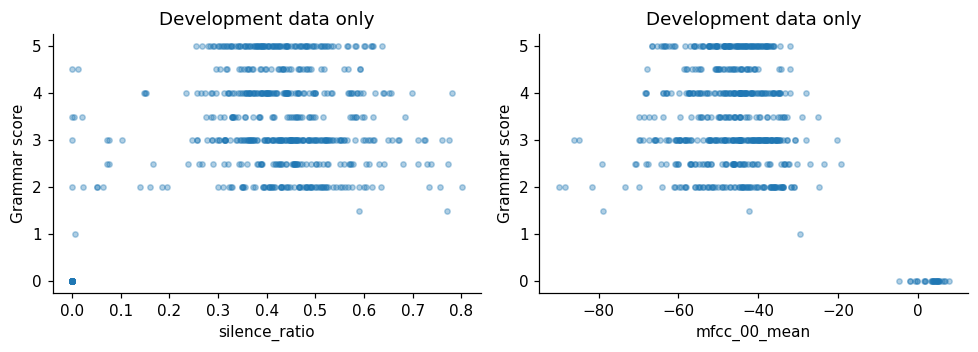

In [8]:
development, holdout, folds = make_validation_split(y)
assignments = np.full(len(y), 'holdout', dtype=object)
assignments[development] = 'development'
fold_ids = np.full(len(y), -1)
for fold, (_, valid) in enumerate(folds):
    fold_ids[valid] = fold
pd.DataFrame({'filename': train.filename, 'partition': assignments, 'cv_fold': fold_ids}).to_csv(RESULTS/'validation_split.csv', index=False)
print(f'Development: {len(development)}, final holdout: {len(holdout)}, CV folds: {len(folds)}')
dev_X = X.iloc[development]
constant = dev_X.columns[dev_X.nunique(dropna=True) <= 1].tolist()
correlations = dev_X.corr().abs()
redundant_pairs = int(np.sum(np.triu(correlations.to_numpy() > .98, k=1)))
print('Constant features on development:', constant)
print('Feature pairs with |correlation| > .98:', redundant_pairs)
print('Missing feature values:', int(dev_X.isna().sum().sum()))
# Correlated descriptors are retained: no validation evidence supports an arbitrary deletion.
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
for ax, feature in zip(axes, ['silence_ratio', 'mfcc_00_mean']):
    ax.scatter(dev_X[feature], y[development], alpha=.35, s=12)
    ax.set(xlabel=feature, ylabel='Grammar score', title='Development data only')
save_plot('02_audio_features.png')

## 11–12. Model experiments and comparison
The experiment table reports pooled out-of-fold development metrics and fold-mean training metrics.
Training fit quality is never used to choose the model. Development CV is used for selection, so its best
score can be optimistic; the separate holdout estimates generalization after the choice is frozen.

In [9]:
experiments, best_name, oof = compare_models(X, y, folds, RESULTS)
display(experiments.drop(columns=['Notes']).round(4))
pd.DataFrame({'filename': train.filename, **oof}).to_csv(RESULTS/'development_oof_predictions.csv', index=False)
print('Selected using development CV:', best_name)

audio | Dummy mean: CV RMSE=1.2359, Pearson=-0.0210


audio | Ridge: CV RMSE=0.8393, Pearson=0.7342


audio | ExtraTrees: CV RMSE=0.7647, Pearson=0.7886


audio | RandomForest: CV RMSE=0.7834, Pearson=0.7767


C:\Users\Kishl\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Kishl\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\Kishl\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
  File "C:\Users\Kishl\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 503, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\Kish

audio | HistGradientBoosting: CV RMSE=0.7820, Pearson=0.7749


,Experiment,Feature Set,Model,CV RMSE,CV Pearson,CV fold RMSE std,Training RMSE,Training Pearson,Seconds
0,Dummy mean,audio,Dummy mean,1.2359,-0.0210,0.0511,1.2352,NaN,0.1796
1,Ridge,audio,Ridge,0.8393,0.7342,0.0175,0.7152,0.8179,0.1927
2,ExtraTrees,audio,ExtraTrees,0.7647,0.7886,0.0200,0.1589,0.9942,3.2113
3,RandomForest,audio,RandomForest,0.7834,0.7767,0.0190,0.3544,0.9687,7.3957
4,HistGradientBoosting,audio,HistGradientBoosting,0.7820,0.7749,0.0143,0.3654,0.9606,2.8352


Selected using development CV: ExtraTrees


## 13. Freeze the selected model
The model family and settings are now fixed. Fit it on development data and evaluate the reserved
holdout once. No changes are made based on that result.

In [10]:
selected, holdout_pred, holdout_metrics, development_metrics = fit_and_evaluate(X, y, best_name, development, holdout)
pd.DataFrame({'filename': train.filename.iloc[holdout], 'actual': y[holdout], 'prediction': holdout_pred}).to_csv(RESULTS/'holdout_predictions.csv', index=False)
joblib.dump({'model': selected, 'development': development, 'holdout': holdout}, MODELS/'holdout_model.joblib')
final_model = clone(make_candidates()[best_name])
with threadpool_limits(limits=4):
    final_model.fit(X, y)
    train_predictions = np.clip(final_model.predict(X), *BOUNDS)
training_metrics = regression_metrics(y, train_predictions)
joblib.dump({'model': final_model, 'features': X.columns.tolist(), 'bounds': BOUNDS,
             'extractor_fingerprint': EXTRACTOR_FINGERPRINT}, MODELS/'grammar_model.joblib')

['models\\grammar_model.joblib']

## 14. Training performance — required Training RMSE
These are predictions from the final model refitted on **all 769 training clips**. They are in-sample
metrics, not estimates of performance on unseen speakers. The holdout score below was measured using
the development-only fitted model before this refit.

In [11]:
print(f"Training RMSE: {training_metrics['RMSE']:.6f}")
print(f"Training Pearson Correlation: {training_metrics['Pearson']:.6f}")

Training RMSE: 0.144228
Training Pearson Correlation: 0.995259


## 15. Validation performance
Both a mean baseline and the frozen selected model are evaluated on the same reserved holdout.
The 95% bootstrap intervals describe sampling uncertainty on this split; they do not account for
unobserved speaker clustering or distribution shift.

Validation RMSE: 0.689112
Validation Pearson Correlation: 0.838489
Holdout mean-baseline RMSE: 1.248823; Pearson undefined for constant predictions


,Subset,Count,RMSE,Pearson
0,zero scores,8,0.0181,NaN
1,nonzero scores,146,0.7077,0.7381


,RMSE,Pearson
95% lower,0.6105,0.7590
95% upper,0.7785,0.8864


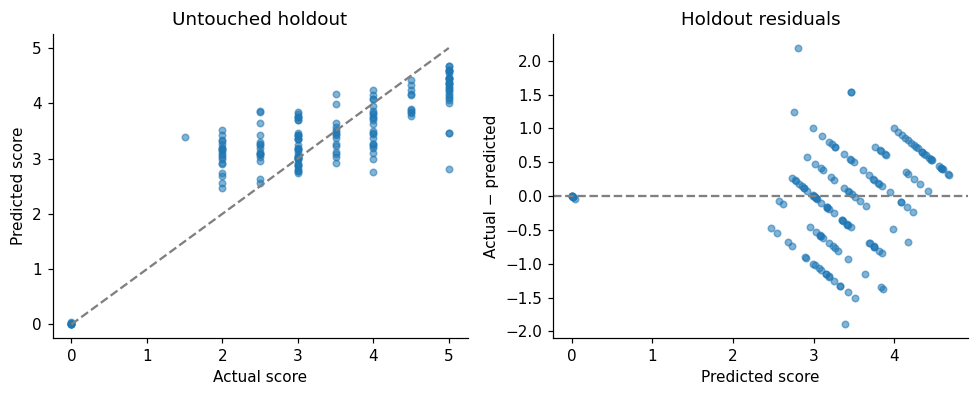

In [12]:
baseline_holdout = regression_metrics(y[holdout], np.full(len(holdout), y[development].mean()))
print(f"Validation RMSE: {holdout_metrics['RMSE']:.6f}")
print(f"Validation Pearson Correlation: {holdout_metrics['Pearson']:.6f}")
print(f"Holdout mean-baseline RMSE: {baseline_holdout['RMSE']:.6f}; Pearson undefined for constant predictions")
subgroup_rows = []
for name, mask in [('zero scores', y[holdout] == 0), ('nonzero scores', y[holdout] > 0)]:
    if mask.any():
        subgroup_rows.append({'Subset': name, 'Count': int(mask.sum()),
                              **regression_metrics(y[holdout][mask], holdout_pred[mask])})
subgroup_metrics = pd.DataFrame(subgroup_rows)
display(subgroup_metrics.round(4))
subgroup_metrics.to_csv(RESULTS/'holdout_subgroups.csv', index=False)
rng = np.random.default_rng(SEED)
bootstrap = []
for _ in range(500):
    idx = rng.integers(0, len(holdout), len(holdout))
    bootstrap.append(regression_metrics(y[holdout][idx], holdout_pred[idx]))
intervals = pd.DataFrame(bootstrap).quantile([.025, .975])
display(intervals.rename(index={.025: '95% lower', .975: '95% upper'}).round(4))
intervals.to_csv(RESULTS/'holdout_bootstrap_intervals.csv')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
axes[0].scatter(y[holdout], holdout_pred, s=18, alpha=.55)
axes[0].plot([0,5], [0,5], '--', color='gray')
axes[0].set(xlabel='Actual score', ylabel='Predicted score', title='Untouched holdout')
axes[1].scatter(holdout_pred, y[holdout]-holdout_pred, s=18, alpha=.55)
axes[1].axhline(0, linestyle='--', color='gray')
axes[1].set(xlabel='Predicted score', ylabel='Actual − predicted', title='Holdout residuals')
save_plot('03_holdout_performance.png')

## 16. Interpretability
Rank candidate features using the development-fitted model (impurity importance for forests,
absolute standardized coefficient for Ridge; development correlation for other estimators).
Then permute the top 15 features three times on the holdout, measuring the increase in RMSE.
This is a post-selection explanation only. It does not trigger feature selection or model tuning.
Correlated features can share importance; association does not prove that a feature measures grammar.

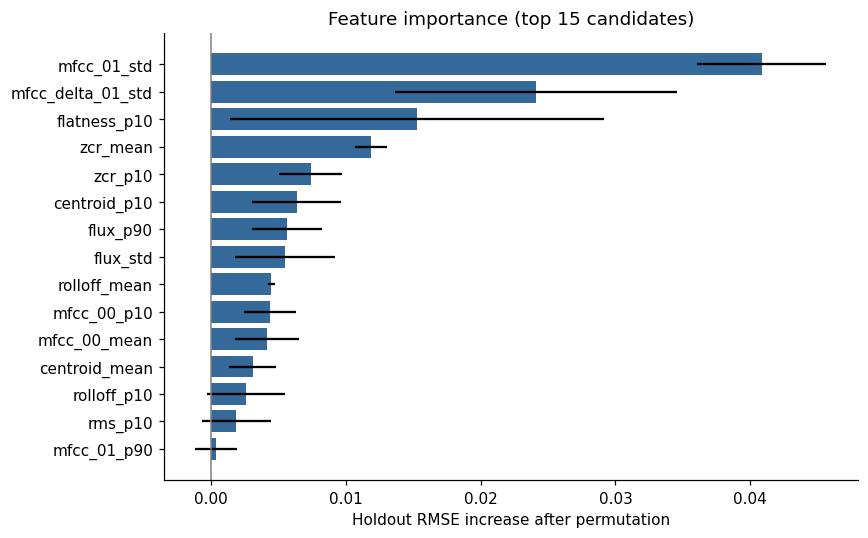

,feature,RMSE increase,repeat std
2,mfcc_01_std,0.0409,0.0048
6,mfcc_delta_01_std,0.0241,0.0105
0,flatness_p10,0.0153,0.0139
4,zcr_mean,0.0119,0.0012
1,zcr_p10,0.0074,0.0024


In [13]:
supported = X.columns[selected.named_steps['variancethreshold'].get_support()]
regressor = selected.steps[-1][1]
if hasattr(regressor, 'feature_importances_'):
    ranking = pd.Series(regressor.feature_importances_, index=supported)
elif hasattr(regressor, 'coef_'):
    ranking = pd.Series(np.abs(regressor.coef_), index=supported)
else:
    ranking = X.iloc[development].corrwith(pd.Series(y[development], index=development)).abs()
top_features = ranking.nlargest(15).index.tolist()
importance_rows = []
permutation_rng = np.random.default_rng(SEED)
with threadpool_limits(limits=4):
    for feature in top_features:
        increases = []
        for repeat in range(3):
            shuffled = X.iloc[holdout].copy()
            shuffled[feature] = permutation_rng.permutation(shuffled[feature].to_numpy())
            score = regression_metrics(y[holdout], selected.predict(shuffled))
            increases.append(score['RMSE']-holdout_metrics['RMSE'])
        importance_rows.append({'feature': feature, 'RMSE increase': np.mean(increases), 'repeat std': np.std(increases)})
importance = pd.DataFrame(importance_rows).sort_values('RMSE increase', ascending=False)
importance.to_csv(RESULTS/'feature_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(8,5))
plot_data = importance.sort_values('RMSE increase')
ax.barh(plot_data.feature, plot_data['RMSE increase'], xerr=plot_data['repeat std'], color='#34699a')
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Holdout RMSE increase after permutation', title='Feature importance (top 15 candidates)')
save_plot('04_feature_importance.png')
display(importance.head(5).round(4))

## 17–18. Final test prediction and submission generation
Predict from the final full-training model, clip to **[0, 5]**, then verify columns, row count,
finite values, unique IDs and exact test order after reading the written CSV back from disk.
Train/test filenames are never joined across splits. The stale 204-row template is used only for its schema.

In [14]:
with threadpool_limits(limits=4):
    test_predictions = np.clip(final_model.predict(X_test), *BOUNDS)
submission = build_submission(test, sample, test_predictions, Path('submission.csv'))
assert len(submission) == 216
print('Validated submission:', submission.shape, '| columns:', submission.columns.tolist())
print('Prediction range:', float(submission.label.min()), 'to', float(submission.label.max()))
display(submission.head())
metrics_report = {'selected_model': best_name, 'feature_count': X.shape[1],
                  'selection': 'Highest development CV Pearson, RMSE tie-break; holdout excluded',
                  'training': training_metrics, 'holdout': holdout_metrics,
                  'baseline_holdout': {**baseline_holdout, 'Pearson': None}, 'development_fit': development_metrics,
                  'development_rows': len(development), 'holdout_rows': len(holdout),
                  'test_predictions': len(submission), 'score_bounds': list(BOUNDS)}
(RESULTS/'metrics.json').write_text(json.dumps(metrics_report, indent=2, allow_nan=False))
pd.DataFrame([{'artifact': 'submission.csv', 'model': best_name, 'rows': len(submission),
               'holdout_rmse': holdout_metrics['RMSE'], 'holdout_pearson': holdout_metrics['Pearson'],
               'status': 'Generated and locally validated; not uploaded to Kaggle'}]).to_csv(RESULTS/'submission_log.csv', index=False)

Validated submission: (216, 2) | columns: ['filename', 'label']
Prediction range: 2.560277777777777 to 4.632472222222222


,filename,label
0,audio_128.wav,3.010611
1,audio_156.wav,3.626000
2,audio_19.wav,3.415389
3,audio_108.wav,2.917444
4,audio_206.wav,3.124222


## 19. Brief report and conclusion
The summary below uses measured results from this execution. No leaderboard performance is claimed.

In [15]:
chosen = experiments.loc[experiments.Model.eq(best_name)].iloc[0]
important_names = ', '.join(importance.head(3).feature)
display(Markdown(f"""
**Approach:** 177 interpretable acoustic descriptors, cached once, with fold-local preprocessing.
**Selected model:** {best_name}; highest development CV Pearson among five predeclared candidates.
Development CV RMSE **{chosen['CV RMSE']:.4f}**, Pearson **{chosen['CV Pearson']:.4f}**.

**Required Training RMSE: {training_metrics['RMSE']:.4f}**; Training Pearson **{training_metrics['Pearson']:.4f}**.
Untouched holdout RMSE **{holdout_metrics['RMSE']:.4f}**, Pearson **{holdout_metrics['Pearson']:.4f}**.
Mean-baseline holdout RMSE **{baseline_holdout['RMSE']:.4f}**.
For the nonzero-score holdout subset, RMSE is **{subgroup_metrics.loc[subgroup_metrics.Subset.eq('nonzero scores'), 'RMSE'].iloc[0]:.4f}**
and Pearson **{subgroup_metrics.loc[subgroup_metrics.Subset.eq('nonzero scores'), 'Pearson'].iloc[0]:.4f}**.
The full-score correlation benefits from the readily distinguishable zero-score examples.

**Explanation:** the strongest measured permutation effects include {important_names}. Acoustic summaries
capture fluency, pauses, articulation and recording properties that may correlate with ratings. They do not
directly detect grammatical errors, and recording conditions/accent may confound the relationship.

**Limitations:** small data, a single outer holdout, no speaker IDs, no full transcript analysis and no
independent leaderboard evaluation. Training metrics are optimistic. Permutation effects are noisy and
shared among correlated features. Zero labels were preserved as supplied; their semantics were not independently verified.

**Output:** `submission.csv` contains all 216 test IDs in exact order with the supplied column schema.
The user confirmed the template IDs were stale. Source, measured experiments, features and plots are saved.
Public GitHub publication and Kaggle upload remain external delivery steps.
"""))


**Approach:** 177 interpretable acoustic descriptors, cached once, with fold-local preprocessing.
**Selected model:** ExtraTrees; highest development CV Pearson among five predeclared candidates.
Development CV RMSE **0.7647**, Pearson **0.7886**.

**Required Training RMSE: 0.1442**; Training Pearson **0.9953**.
Untouched holdout RMSE **0.6891**, Pearson **0.8385**.
Mean-baseline holdout RMSE **1.2488**.
For the nonzero-score holdout subset, RMSE is **0.7077**
and Pearson **0.7381**.
The full-score correlation benefits from the readily distinguishable zero-score examples.

**Explanation:** the strongest measured permutation effects include mfcc_01_std, mfcc_delta_01_std, flatness_p10. Acoustic summaries
capture fluency, pauses, articulation and recording properties that may correlate with ratings. They do not
directly detect grammatical errors, and recording conditions/accent may confound the relationship.

**Limitations:** small data, a single outer holdout, no speaker IDs, no full transcript analysis and no
independent leaderboard evaluation. Training metrics are optimistic. Permutation effects are noisy and
shared among correlated features. Zero labels were preserved as supplied; their semantics were not independently verified.

**Output:** `submission.csv` contains all 216 test IDs in exact order with the supplied column schema.
The user confirmed the template IDs were stale. Source, measured experiments, features and plots are saved.
Public GitHub publication and Kaggle upload remain external delivery steps.
